In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("books_full.csv")
df.head()

,title,price,rating,availability,detail_url,category,upc
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,a897fe39b1053632
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,90fa61229261140a
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,6957f44c3847a760
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,e00eb4fd7b871a48
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,4165285e1663650f


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1000 non-null   str    
 1   price         1000 non-null   float64
 2   rating        1000 non-null   int64  
 3   availability  1000 non-null   str    
 4   detail_url    1000 non-null   str    
 5   category      1000 non-null   str    
 6   upc           1000 non-null   str    
dtypes: float64(1), int64(1), str(5)
memory usage: 54.8 KB


In [4]:
df.describe()

,price,rating
count,1000.00000,1000.000000
mean,35.07035,2.923000
std,14.44669,1.434967
min,10.00000,1.000000
25%,22.10750,2.000000
50%,35.98000,3.000000
75%,47.45750,4.000000
max,59.99000,5.000000


# Exploratory Data Analysis: Books Dataset

## Questions
1. Which categories have the most books?
2. Which categories are the most expensive on average?
3. Does a higher rating mean a higher price?
4. Are there price outliers?
5. Is any category rated better than the rest?

In [22]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate UPCs:", df["upc"].duplicated().sum())

Duplicate rows: 0
Duplicate UPCs: 0


In [6]:
print(df["category"].nunique())
df["category"].value_counts()

50


category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Horror                 17
Womens Fiction         17
Science Fiction        16
Science                14
Music                  13
Business               12
Travel                 11
Thriller               11
Philosophy             11
Humor                  10
Autobiography           9
Art                     8
Religion                7
Psychology              7
Spirituality            6
New Adult               6
Christian Fiction       6
Self Help               5
Biography               5
Sports and Games        5
Health                  4
Politics                3
Contemporary            3
Chr

In [7]:
df["availability"].value_counts()

availability
In stock    1000
Name: count, dtype: int64

category
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64


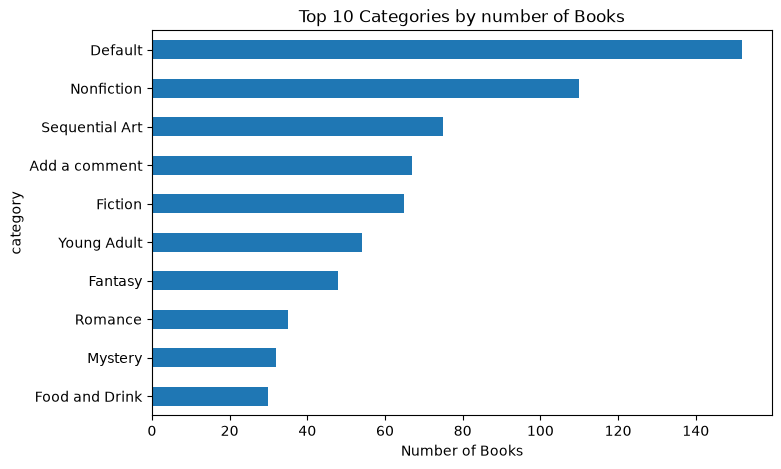

In [8]:
##Q1]
top_categories = df["category"].value_counts().head(10)
print(top_categories)

top_categories.plot(kind="barh", figsize=(8, 5), title="Top 10 Categories by number of Books")
plt.gca().invert_yaxis()
plt.xlabel("Number of Books")
plt.show()

### Finding: category sizes
"Default" (152 books) and "Nonfiction" (110) are the largest categories, followed by "Sequential Art" (75) and "Add a comment" (67). "Default" and "Add a comment" look like catch-all labels for books without a real genre, together about 22% of the data. There are 50 categories in total, and 15 of them have fewer than 5 books.

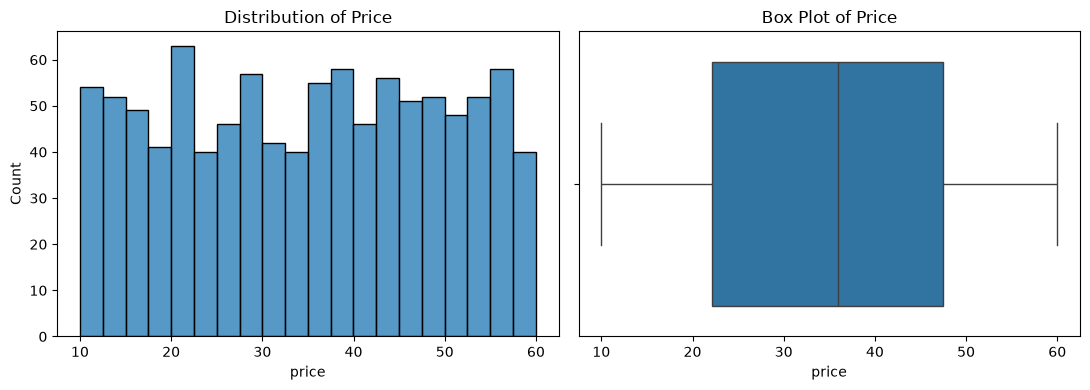

In [ ]:
##Q4]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["price"], bins=20, ax=axes[0])
axes[0].set_title("Distribution of Price")
sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Box Plot of Price")
plt.tight_layout()
plt.show()

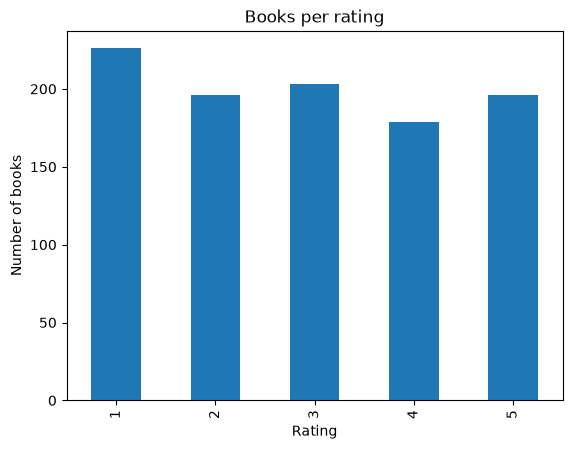

In [ ]:
##Rating distribution] (For Q3 & Q5)
df["rating"].value_counts().sort_index().plot(kind="bar", title="Books per rating")
plt.xlabel("Rating")
plt.ylabel("Number of books")
plt.show()

### Finding: price and rating distributions
Prices are spread fairly evenly between £10 and £60 (no bell shape and no
extreme values), and the box plot shows no outliers. Ratings are also spread
across all five levels without one dominant rating.

In [ ]:
##Q3]
print(df["price"].corr(df["rating"]))
df.groupby("rating")["price"].mean().round(2)

0.028166239485872983


rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: price, dtype: float64

Average price is similar at every rating level (£34.56 to £36.09), with no
upward trend from 1 to 5 stars.

In [ ]:
##Q2]
cat_price = df.groupby("category")["price"].agg(["count", "mean"]).round(2)
cat_price = cat_price[cat_price["count"] >= 10].sort_values("mean", ascending=False)
cat_price.head(10)

,count,mean
category,,
Travel,11,39.79
Fantasy,48,39.59
History,18,37.29
Womens Fiction,17,36.79
Classics,19,36.55
Fiction,65,36.07
Poetry,19,35.97
Horror,17,35.95
Add a comment,67,35.80


In [13]:
from scipy import stats

big = df[df["category"].map(df["category"].value_counts()) >= 10]
groups = [g["price"].values for _, g in big.groupby("category")]
f_stat, p_value = stats.f_oneway(*groups)
print(f"F = {f_stat:.2f}, p = {p_value:.3f}")

F = 0.61, p = 0.930


### Finding: price by category
A one-way ANOVA on categories with 10+ books gave F = 0.61, p = 0.930.
There is no statistically significant difference in average price between
genres. Travel (£39.79) and Fantasy (£39.59) look most expensive, but the
gap is within normal random variation. Genre does not explain price here.

In [14]:
r, p = stats.pearsonr(df["price"], df["rating"])
print(f"correlation r = {r:.3f}, p = {p:.3f}")

correlation r = 0.028, p = 0.374


In [15]:
cat_price.tail(5)

,count,mean
category,,
Childrens,29,32.64
Business,12,32.46
Mystery,32,31.72
Thriller,11,31.43
Food and Drink,30,31.41


### Finding: cheapest categories
Food and Drink (£31.41), Thriller (£31.43) and Mystery (£31.72) have the lowest
average prices, but combined with the ANOVA result (p = 0.930) these gaps are
not statistically meaningful. Category averages range from £31.41 to £39.79,
which is consistent with random variation around the overall mean of £35.07.

### Finding: price vs rating
Pearson correlation between price and rating is r = 0.028 (p = 0.374).
There is no statistically significant relationship. Higher-rated books are
not priced higher or lower than lower-rated ones.

In [17]:
q1, q3 = df["price"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["price"] < low) | (df["price"] > high)]
print(f"Fences: {low:.2f} to {high:.2f}")
print(f"Outliers: {len(outliers)}")

Fences: -15.92 to 85.48
Outliers: 0


### Finding: outliers
Using the IQR rule (1.5 x IQR), the fences are -£15.92 to £85.48. All 1,000
prices (£10.00 to £59.99) fall inside, so there are no price outliers. Prices
are spread fairly evenly across the range, with no extreme values to remove.

In [ ]:
##Q5]
groups = [g["rating"].values for _, g in big.groupby("category")]
f_stat, p_value = stats.f_oneway(*groups)
print(f"F = {f_stat:.2f}, p = {p_value:.3f}")

F = 1.06, p = 0.390


### Finding: rating by category
A one-way ANOVA on ratings (categories with 10+ books) gave F = 1.06, p = 0.390.
No category is rated significantly higher than the others.

## Conclusions

**Dataset:** 1,000 books scraped from books.toscrape.com, 7 columns, no missing values and no duplicates. All 1,000 books are "In stock", so the availability column carries no information.

| Question | Finding |
|---|---|
| 1. Which categories have the most books? | Default (152), Nonfiction (110) and Sequential Art (75). "Default" and "Add a comment" look like placeholder categories for books without a genre, together about 22% of the data. |
| 2. Which categories are the most expensive? | Travel (£39.79) and Fantasy (£39.59) lead, but the ANOVA (p = 0.930) shows the differences are not statistically significant. |
| 3. Does a higher rating mean a higher price? | No. r = 0.028, p = 0.374. |
| 4. Are there price outliers? | None. The IQR fences are -£15.92 to £85.48, and all prices lie within £10.00 to £59.99. |
| 5. Is any category rated better? | No. The ANOVA on rating gives F = 1.06, p = 0.390. |

**Overall:** price and rating look randomly distributed across this dataset. Neither genre nor rating explains price. This is likely because the site's prices and ratings are not real market data, and it is itself a useful result: not every question has a pattern, and testing is how you find out.

**Limitations:** category tests used only categories with 10 or more books. The data is a single snapshot from a practice site, so the findings do not describe real book markets.